# 06 — Test caméra partagée (Windows)

Utilise la classe de capture **déjà présente dans Assetto Corsa Gym**, sans copier ni modifier le plugin. Capture depuis mémoire partagée Windows (si activée côté `sensors_par`).

In [31]:
from pathlib import Path
import sys
CWD=Path.cwd().resolve()
REPO=next((p for p in [CWD,*CWD.parents] if (p/'assetto_corsa_gym'/'assetto_corsa_gym'/'AssettoCorsaEnv').is_dir()),None)
if REPO is None:
    raise FileNotFoundError('Ouvre le depot IA_projet_Ouarti_ds_github dans VS Code : son dossier assetto_corsa_gym doit exister.')
PROJECT=REPO/'Code'
if not PROJECT.is_dir():
    raise FileNotFoundError('Dossier Code absent : extraire Code a la racine du depot.')
GYM_ROOT=REPO/'assetto_corsa_gym'/'assetto_corsa_gym'
print('Depot :',REPO)
print('Notebooks :',PROJECT)
print('Python :',sys.version.split()[0],sys.executable)


Depot : C:\Users\elkat\Documents\Github\IA_projet_Ouarti_ds_github
Notebooks : C:\Users\elkat\Documents\Github\IA_projet_Ouarti_ds_github\Code
Python : 3.9.13 c:\Users\elkat\AppData\Local\Programs\Python\Python39\python.exe


In [32]:

import socket
import time

HOST = "127.0.0.1"
PORT = 2347

print("Connexion au serveur de gestion...")

try:
    with socket.create_connection((HOST, PORT), timeout=10) as s:
        s.settimeout(10)

        print("Connexion TCP établie")
        print("Envoi de get_config...")

        debut = time.monotonic()
        s.sendall(b"get_config")

        reponse = s.recv(65536)

        print("Durée :", round(time.monotonic() - debut, 2), "s")
        print("Octets reçus :", len(reponse))

        if reponse:
            print("Réponse :", reponse.decode("utf-8", errors="replace")[:2000])
        else:
            print("Le serveur a fermé la connexion sans répondre.")

except socket.timeout:
    print("ERREUR : serveur connecté mais aucune réponse après 10 secondes.")

except OSError as e:
    print("ERREUR réseau :", repr(e))


Connexion au serveur de gestion...
Connexion TCP établie
Envoi de get_config...
Durée : 0.05 s
Octets reçus : 1043
Réponse : {'ego_sampling_freq_event_name': 'Local\\EgoSamplingFreqEvent', 'screen_capture_verbose': False, 'screen_capture_worker': 'screen_capture_worker.py', 'sampling_time': 0.02, 'opponents_server_host_name': '0.0.0.0', 'screen_capture_freq': 25, 'enable_alternative_python_interpreter': True, 'sampling_freq': 50, 'ego_server_port': 2345, 'enable_profiler': False, 'telemetry_sampling_freq': 0, 'config_python_executable': 'C:\\Users\\elkat\\AppData\\Local\\Programs\\Python\\Python39\\python.exe', 'opponents_server_port': 2346, 'color_mode': 'gray', 'vjoy_executed_by_server': False, 'relocate_screen': True, 'final_image_width': 320, 'version': '0.0.1', 'screen_capture_save_to_disk': False, 'config_python_env_name': 'p309', 'ego_sampling_freq': 25, 'trigger_image_capture_event_name': 'Local\\TriggerImageCapture', 'final_image_height': 240, 'ego_server_host_name': '0.0.0.0'

In [33]:
import socket, json, ast, time
HOST='127.0.0.1'
PORT_UDP=2345
PORT_TCP=2347

def management(message,timeout=3):
    with socket.create_connection((HOST,PORT_TCP),timeout=timeout) as s:
        s.settimeout(timeout);s.sendall(message.encode('ascii'))
        data=b''
        end=time.monotonic()+timeout
        while time.monotonic()<end and len(data)<1024*1024:
            try:chunk=s.recv(65536)
            except socket.timeout:break
            if not chunk:break
            data+=chunk
            try:return json.loads(data)
            except (json.JSONDecodeError, UnicodeDecodeError):pass
            try:return ast.literal_eval(data.decode('utf8'))
            except (ValueError,SyntaxError,UnicodeDecodeError):pass
        if data:
            raise RuntimeError('Reponse TCP incomplete : '+repr(data[:160]))
    raise RuntimeError('Pas de reponse sur le port management')

def open_telemetry(timeout=4):
    s=socket.socket(socket.AF_INET,socket.SOCK_DGRAM);s.settimeout(.4)
    s.connect((HOST,PORT_UDP))
    end=time.monotonic()+timeout
    while time.monotonic()<end:
        s.send(b'connect')
        try:response=s.recv(2**18)
        except socket.timeout:continue
        if response==b'identified':return s
    s.close()
    raise TimeoutError('Pas de confirmation UDP sur 2345 : verifier jeu en piste et plugin sensors_par.')

def next_packet(s,timeout=3):
    end=time.monotonic()+timeout
    while time.monotonic()<end:
        try:message=s.recv(2**18)
        except socket.timeout:continue
        if message==b'disconnect':raise ConnectionError('Le jeu a ferme le flux UDP')
        if message==b'identified':continue
        raw=json.loads(message)
        if not isinstance(raw,dict):continue
        raw['_capture_wall_time']=time.time()
        return raw
    raise TimeoutError('Aucun echantillon recu.')

def close_telemetry(s):
    if s is not None:
        try:s.send(b'disconnect')
        except OSError:pass
        s.close()


In [34]:
config=management('get_config')
static=management('get_static_info')
print('Plugin :')
for key in ['ego_sampling_freq','sampling_freq','vjoy_executed_by_server','screen_capture_enable','color_mode','final_image_width','final_image_height']:
    print(' ',key,':',config.get(key))
print('Session :',static.get('TrackName'),static.get('TrackConfiguration'), '/', static.get('CarName'))


Plugin :
  ego_sampling_freq : 25
  sampling_freq : 50
  vjoy_executed_by_server : False
  screen_capture_enable : True
  color_mode : gray
  final_image_width : 320
  final_image_height : 240
Session : ks_barcelona layout_gp / abarth500


Image : sequence 5530 timestamp 1794506641.9188113
Taille : (240, 320) Intensite max : 255


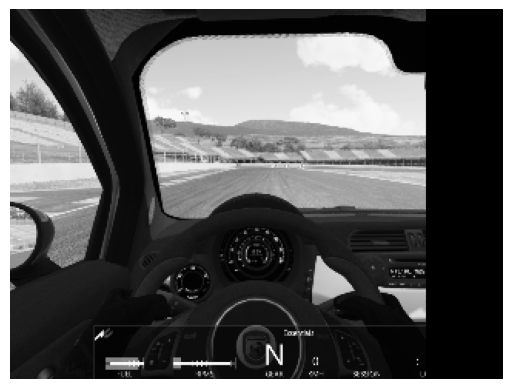

In [35]:
import sys
if not config.get('screen_capture_enable'):
    raise RuntimeError('Activer screen_capture_enable dans le plugin sensors_par du jeu. Ce notebook ne modifie pas le plugin.')
plugin_path=GYM_ROOT/'AssettoCorsaPlugin'/'plugins'/'sensors_par'
sys.path.insert(0,str(plugin_path))
from dual_buffer import GrabberSharedMemoryDualBuffer
import numpy as np,matplotlib.pyplot as plt
camera=GrabberSharedMemoryDualBuffer(int(config['final_image_width']),int(config['final_image_height']),str(config['color_mode']))
if hasattr(camera,'get_timed_image'):
    seq,stamp,image=camera.get_timed_image()
    if stamp<=0:raise RuntimeError('Capture non horodatee : worker absent ou inactif.')
    print('Image : sequence',seq,'timestamp',stamp)
else:
    _,_,image=camera.get_active_image()
print('Taille :',image.shape, 'Intensite max :',image.max())
if config['color_mode']=='bgr':
    plt.imshow(image[:,:,::-1])
else:
    plt.imshow(image,cmap='gray')
plt.axis('off');plt.show()
